### All imports

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

### Reading file

In [3]:
df = pd.read_csv('advertising_funnel.csv')
df

,user_id,ad_channel,funnel_stage,price,profit,os,timestamp
0,991236,native,interest,2.0,NaN,Android,150000
1,335514,banner,interest,0.5,NaN,Android,150000
2,619571,search,consideration,1.5,NaN,iOS,150000
3,387356,search,interest,1.5,NaN,iOS,150000
4,399556,search,interest,1.5,NaN,iOS,150000
...,...,...,...,...,...,...,...
3845702,929180,search,intent,1.5,NaN,iOS,224682
3845703,1034498,search,intent,1.5,NaN,iOS,225430
3845704,947521,organic_traffic,consideration,0.0,NaN,Android,225482
3845705,720354,organic_traffic,purchase,0.0,50.0,Android,225495


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3845707 entries, 0 to 3845706
Data columns (total 7 columns):
 #   Column        Dtype  
---  ------        -----  
 0   user_id       int64  
 1   ad_channel    str    
 2   funnel_stage  str    
 3   price         float64
 4   profit        float64
 5   os            str    
 6   timestamp     int64  
dtypes: float64(2), int64(2), str(3)
memory usage: 205.4 MB


In [5]:
df.isna().sum()

user_id               0
ad_channel            0
funnel_stage          0
price             22588
profit          3840830
os                    0
timestamp             0
dtype: int64

In [6]:
df[df['price'].isna()]['ad_channel'].value_counts()

ad_channel
other    22588
Name: count, dtype: int64

In [7]:
print(df['ad_channel'].value_counts())
print(df['funnel_stage'].value_counts())
print(df['os'].value_counts())

ad_channel
search             1491205
video               655068
banner              576169
organic_traffic     531584
partner_network     387430
native              117575
rich                 64088
other                22588
Name: count, dtype: int64
funnel_stage
interest         3219813
consideration     340106
intent            280911
purchase            4877
Name: count, dtype: int64
os
Android    2032032
iOS        1813675
Name: count, dtype: int64


In [8]:
df['ad_channel'] = df['ad_channel'].str.strip().str.lower()
df['funnel_stage'] = df['funnel_stage'].str.strip().str.lower()
df['os'] = df['os'].str.strip().str.lower()

In [9]:
funnel = (
    df.groupby(['ad_channel', 'funnel_stage'])['user_id']
      .nunique()
      .unstack(fill_value=0)
)

funnel

funnel_stage,consideration,intent,interest,purchase
ad_channel,,,,
banner,47541,7625,92003,688
native,12597,412,19381,37
organic_traffic,53592,9163,78707,542
other,1813,232,3216,43
partner_network,24721,4420,66234,450
rich,4657,1238,8922,22
search,134305,27481,224668,3090
video,60880,58,97961,5


In [10]:
actions_per_moment = (
    df.groupby(['user_id', 'timestamp'])
      .size()
      .reset_index(name='actions_count')
)

actions_per_moment.head()

,user_id,timestamp,actions_count
0,2,184320,1
1,3,171761,1
2,4,198271,1
3,5,197181,1
4,5,202361,1


In [11]:
actions_per_moment['actions_count'].describe()

count    991900.000000
mean          3.877112
std          39.676489
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         599.000000
Name: actions_count, dtype: float64

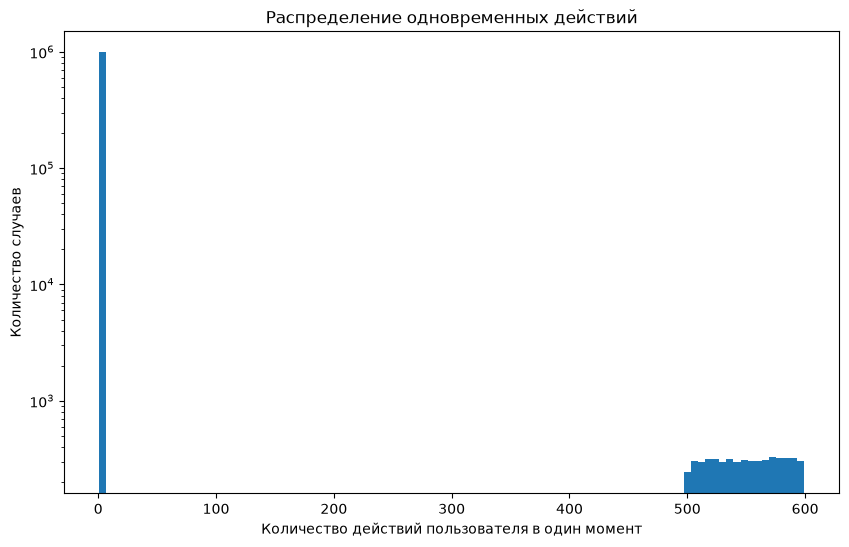

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    actions_per_moment['actions_count'],
    bins=100
)

plt.yscale('log')

plt.xlabel('Количество действий пользователя в один момент')
plt.ylabel('Количество случаев')
plt.title('Распределение одновременных действий')

plt.show()

In [13]:
fraud_pairs = actions_per_moment[
    actions_per_moment['actions_count'] >= 499
]

In [14]:
df = df.merge(
    actions_per_moment,
    on=['user_id', 'timestamp'],
    how='left'
)

In [15]:
fraud_data = df[df['actions_count'] >= 499].copy()

clean_data = df[df['actions_count'] < 499].copy()

In [16]:
fraud_percent = (
    fraud_data['user_id'].nunique()
    / df['user_id'].nunique()
    * 100
)

fraud_percent

0.816862263558428

In [17]:
fraud_data.to_csv(
    'fraud_data.csv',
    index=False
)

In [18]:
clean_data.to_csv(
    'advertising_funnel_clean.csv',
    index=False
)